# FMDV model

The model is based on the model in [Jolles et al, 2021](https://science.org/doi/10.1126/science.abd2475), simplified by (in order of decreasing complexity):

1. All waiting times are exponential distributions, with linear chain trick to approximate the gamma distribution for carrier duration. In the original, waning of maternal immunity, progression, and recovery from acute infection were gamma distributions.
2. The birth rate is constant in time. In the original, the birth rate is seasonal.

This model will track individuals, so that age-dependent mortality and reproduction can be incorporated. This will also allow us to track infection & carrier status by age class, allowing us to confirm that the re-infection portion of the model (once added) successfully re-creates the age-structed carrier class patterns observed.

## Parameter values

These are mostly from the supplmental material to Jolles et al, 2021.

| Parameter                     |          all |          SAT1 |          SAT2 |          SAT3 |
|:------------------------------|--------------:|--------------:|--------------:|--------------:|
| Death mean waiting time       |   4.387 year  |             — |             — |             — |
| Birth mean waiting time       |   4.387 year  |             — |             — |             — |
| Waning mean waiting time      |   0.37  year  |             — |             — |             — |
| Acute transmission rate       |             — |   2.8   day⁻¹ |   1.6   day⁻¹ |   1.2   day⁻¹ |
| Carrier transmission rate     |             — |   0.028 day⁻¹ |   0.003 day⁻¹ |   0.012 day⁻¹ |
| Progression mean waiting time |             — |   0.5   day   |   1.3   day   |   2.8  day    |
| Recovery mean waiting time    |             — |   5.7  day    |   4.6  day    |   4.2  day    |
| Recovery shape parameter    |             — |   11.8      |   8.7      |   11.8      |
| Carrier probability           |             — |   0.90        |   0.44        |   0.67        |
| Carrier recovery              |             — | 243    day    | 180    day    | 174    day    |
| Carrier shape parameter              |             — |        — | 3*        |       — |

**Note the different time units!**

We will take all of the waiting times to be exponential distributions. In Jolles et al, 2021, all except death & birth were gamma distributions, which have an extra shape parameter.

Because we will use the linear chain trick, we can only use integers for the shape parameters. We will start with carrier shape parameter, using shape = 3 (as opposed to shape - 3.2) in the original model.

### Birth and death

Birth in Jolles et al., 2021 was age dependent (menarchy at age 4 years) and seasonal, but scaled so that the expected population size is constant in time. Here, the mean waiting time is the same as for death so that the expected population size is constant in time. (In Jolles et al, 2021, the sex of hosts was also tracked and only females gave birth. Here, we will not track sex.)

Death in Jolles et al, 2021 was age dependent, from the estimated age-dependent annual survival. Here, the mean waiting time is the mean lifetime calculated from that age-dependent annual survival.

First, we will create the individual model with the same parameterization as the population model; once this has been accomplished, we will add in the age-dependet mortality, which appears to very important for SAT3 persistence.

### Infection

The force of infection is
$$
\lambda_\text{infection} =
\frac{\beta_\text{acute}}{N} I
+ \frac{\beta_\text{carrier}}{N} C,
$$
where $\beta$ are the transmission rates, $I$ is the number of infectious hosts, $C$ is the number of carrier hosts, and $N$ is the **initial** population size. The mean waiting time for infection is then
$$
\frac{1}{\lambda_\text{infection}}.
$$
We chose to scale the transmission rates by initial population size because we first chose the density-dependent force of infection and then wanted $R_0$ to be independent of initial population size. (The logic is a bit muddled. An alternative would be use the frequency-dependent force of infection using the same formula but with $N$ being the **current** population size.)

### Recovery

Acute infection in Jolles et al, 2021 was split between a first exposed class followed by the Acute infection in Jolles et al, 2021 was split between a first exposed class followed by the infectious class. The transition from exposed to infectious was called progression and the transition out of infectious was called recovery.

## Model setup

In [1]:
import abc
import collections
from dataclasses import dataclass

import numpy
import pandas
import scipy
import joblib

import matplotlib.pyplot as plt
import seaborn

In [2]:
def simulate(events, time_span, herd_start, seed=None):
    '''Simulate with Gillespie's next-reaction method.
    `events` is a list of all the events that can occur.
    `time_span` is `(time_start, time_end)`.
    `state_start` is the state at `time_start`.
    `seed` is for the random-number generator.'''
    # Simplify by ensuring events is not empty
    assert len(events) > 0
    (time, time_end) = time_span
    # Simplify by ensuring `time_end` is finite
    assert numpy.isfinite(time_end)
    herd = herd_start.copy()
    # Build the random-number generator
    rng = numpy.random.default_rng(seed)
    # Initialize storage of the simulation history
    history = History()
    while True:
       
        n_inf = history.update(time, herd)
        
        if time >= time_end:
            break  # Exit the `while` loop
        if n_inf == 0:
           break
        
        herd_event_next = []
        buff_event_next = collections.namedtuple("buff_event_next", ['buff_index','time','event_type'])
        
        for i in range(len(herd)):
            waiting_times = [
                event.get_waiting_time(rng, herd, herd[i])
                for event in events
                ]
            t_next = min(waiting_times)
            i_next = numpy.argmin(waiting_times)
            next_e = buff_event_next(i, t_next, events[i_next])
            herd_event_next.append(next_e)
            
        next_event = min(herd_event_next, key = key_tune)   
        time_next = time + next_event.time
        if time_next <= time_end:
            time = time_next
            # Find the position of the minimum in `waiting_times`
            # to find the corresponding event in `events`
            event_next = next_event.event_type
            herd = event_next.get_state_change(rng, herd, next_event.buff_index)

            for i in herd:
                i.age_update(next_event.time)
        else:
            # The next event is after `time_end`
            time = time_end
        
    return history.to_dataframe()

In [3]:
def key_tune(obj):
    return(obj.time)

In [4]:
@dataclass
class Buffalo:
    state: str
    age: float

    def age_update(self, time_step):
        self.age += time_step

    def __post_init__(self):
        self.age = float(self.age)

In [5]:
class Event(metaclass=abc.ABCMeta):
    '''Base for a kind of event.'''

    @abc.abstractmethod
    def get_waiting_time(self, rng, herd, buff):
        '''Get a random sample of the waiting time to the next event.'''
        raise NotImplementedError

    @abc.abstractmethod
    def get_state_change(self, rng, herd, index):
        '''Get the change to `state` from this event occurring.'''
        raise NotImplementedError

In [6]:
class Waning(Event):
    '''Waning of 'maternal_immunity' to 'susceptible'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['waning_mean_waiting_time']

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'maternal_immunity':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'susceptible'
        return herd

In [7]:
class Birth(Event):
    '''Waning of 'maternal_immunity' to 'susceptible'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['birth_mean_waiting_time']

    def get_waiting_time(self, rng, herd, buff):
        if buff.age > 0:
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        if herd[index].state in ['maternal_immunity', 'susceptible', 'exposed', 'infectious']:
            herd.append(Buffalo('susceptible', 0))
        else:
            herd.append(Buffalo('maternal_immunity', 0))
        return herd

In [8]:
class Death(Event):
    '''Waning of 'maternal_immunity' to 'susceptible'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['death_mean_waiting_time']

    def get_waiting_time(self, rng, herd, buff):
        return rng.exponential(self.mean_waiting_time)
        
    def get_state_change(self, rng, herd, index):
        del herd[index]
        return herd

In [9]:
class Infection(Event):
    '''Infection of an individual from susceptible class.'''

    def __init__(self, parameters, herd):
        self.beta_acute = parameters['acute_transmission_rate'] / collections.Counter(i.state for i in herd).total()
        self.beta_carrier = parameters['carrier_transmission_rate'] / collections.Counter(i.state for i in herd).total()

    def get_waiting_time(self, rng, herd, buff):

        if buff.state == 'susceptible':
            infectious = collections.Counter(i.state for i in herd)['infectious']
            carriers = collections.Counter(i.state for i in herd)['carrier_1*'] + collections.Counter(i.state for i in herd)['carrier_2*'] + collections.Counter(i.state for i in herd)['carrier_3*'] 
            foi = self.beta_acute * infectious + self.beta_carrier * carriers
            try:
                self.mean_waiting_time = 1 / foi
            except ZeroDivisionError:
                return numpy.inf
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'exposed'
        return herd

In [10]:
class Progression(Event):
    '''Progression of infection from latent to infectious period'.'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['progression_mean_waiting_time']

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'exposed':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'infectious'
        return herd

In [11]:
class Recovery(Event):
    '''Progression of infection from infectious to carrier or recovered class'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['recovery_mean_waiting_time']
        self.carrier_probability = parameters['carrier_probability']

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'infectious':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = rng.choice(['carrier_1', 'recovered'],
                           p=[self.carrier_probability, 1-self.carrier_probability])
        return herd

In [12]:
class Carrier_Recovery_1(Event):
    '''Progression of infection from infectious to carrier or recovered class'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'carrier_1':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'carrier_2'
        return herd

In [13]:
class Carrier_Recovery_2(Event):
    '''Progression of infection from infectious to carrier or recovered class'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'carrier_2':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'carrier_3'
        return herd

In [14]:
class Carrier_Recovery_3(Event):
    '''Progression of infection from infectious to carrier or recovered class'''

    def __init__(self, parameters):
        self.mean_waiting_time = parameters['carrier_recovery_mean_waiting_time']/3

    def get_waiting_time(self, rng, herd, buff):
        if buff.state == 'carrier_3':
            return rng.exponential(self.mean_waiting_time)
        else:
            return numpy.inf

    def get_state_change(self, rng, herd, index):
        herd[index].state = 'recovered'
        return herd

In [15]:
class History:
    '''Record simulation history.'''

    def __init__(self):
        self.time = []
        self.state = []

    def update(self, time, herd):
        '''Update for the current `time` and `state`.'''
        self.time.append(time)

        new_states = collections.Counter(
            'carrier' if b.state in {'carrier_1','carrier_2','carrier_3'} else b.state
            for b in herd)

        self.state.append(new_states)
        
        return(new_states['exposed'] + new_states['infectious'] + new_states['carrier'])

    def to_dataframe(self):
        '''Convert to something more useful.'''
        index = pandas.Index(self.time, name='time')
        df = pandas.DataFrame(self.state, index=index)
        report_states = ['maternal_immunity','susceptible','exposed','infectious','carrier','recovered']
        return df.reindex(columns=report_states).fillna(0).astype(int)

In [16]:
parameters = {
  'birth_mean_waiting_time': 4.387*365.25,    # units: day
  'death_mean_waiting_time': 4.387*365.25,    # units: day
  'waning_mean_waiting_time': 0.37*365.25,    # units: day
   # Parameters for sat1
  'acute_transmission_rate': 2.8,        # units: 1/day
  'carrier_transmission_rate': 0.028,    # units: 1/day
  'progression_mean_waiting_time': 0.5,  # units: day
  'recovery_mean_waiting_time': 5.7,     # units: day
  'carrier_probability': 0.9,            # units: none
  'carrier_recovery_mean_waiting_time': 243,  # units: day
}


herd_start = []

n_buff = 998
states = ['maternal_immunity','susceptible',
          'exposed','infectious',
          'carrier_1','carrier_2','carrier_3',
          'recovered']
p_start = [0.06156, 0.219052, 0, 0, 0.027334/3, 0.027334/3, 0.027334/3, 0.692054]

rng = numpy.random.default_rng(12)

for i in range(n_buff):
    buff_state = str(rng.choice(states, p = p_start))
    buff_age = rng.uniform(0,14)
    herd_start.append(Buffalo(buff_state, buff_age))

herd_start.append(Buffalo('infectious', rng.uniform(0,14)))
herd_start.append(Buffalo('infectious', rng.uniform(0,14)))
   

events = (
    Birth(parameters),
    Death(parameters),
    Waning(parameters),
    Infection(parameters, herd_start),
    Progression(parameters),
    Recovery(parameters),
    Carrier_Recovery_1(parameters),
    Carrier_Recovery_2(parameters),
    Carrier_Recovery_3(parameters),
)

herd_start[-1]

Buffalo(state='infectious', age=2.905247813731679)

In [17]:
result_sat1 = simulate(events, (0, 100), herd_start)

<Axes: xlabel='time'>

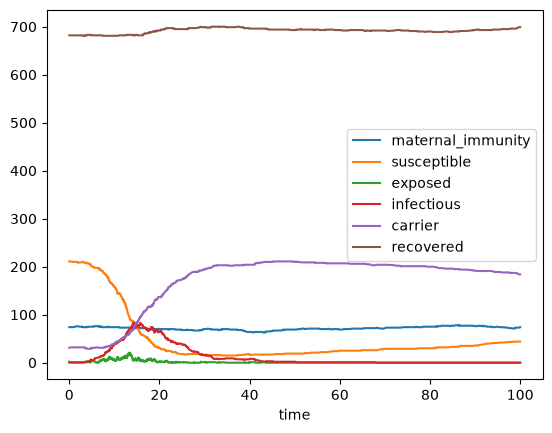

In [18]:
result_sat1.plot()

In [19]:
result_sat1[0:3]

,maternal_immunity,susceptible,exposed,infectious,carrier,recovered
time,,,,,,
0.000000,74,211,0,2,31,682
0.355138,74,211,0,1,32,682
0.762644,74,210,0,1,32,682
